# Lupa · notebook ejecutado (evidencia)

Copia ejecutada el **26 de noviembre de 2026** por Martín Murillo, con la salida de cada celda: verificación del LLM, prueba de las tools, demo del agente (5.1 a 5.3), interfaz web y la evaluación completa de 12 tareas con y sin skills (secciones 7.1 a 7.4).

- Los avisos `WARNING` muestran el **respaldo automático de modelos** en acción: cuando un modelo de Gemini estaba saturado (503) o sin cuota diaria (429), Lupa pasó solo al siguiente.
- La celda «Arreglo» después de la instalación ya no hace falta: ese cambio quedó en `src/lupa/llm/gemini.py`.
- Para ejecutarlo de nuevo usa el notebook limpio: [`02_demo_lupa.ipynb`](02_demo_lupa.ipynb).
- Resultados de la evaluación: [`eval/resultados/`](../eval/resultados/).

# Lupa: agente analista de datos abiertos de Colombia

**Proyecto final de Inteligencia Artificial** · Línea 4: Agentes inteligentes con tools y skills
**Equipo:** Adrián Campos, David Celorio y Martín Murillo · Universidad Santiago de Cali

Lupa responde preguntas en español sobre los datos de [datos.gov.co](https://www.datos.gov.co): encuentra el conjunto de datos, lo consulta, lo analiza con código, hace gráficas, busca contexto en la web y entrega un informe con fuentes.

| Sección | Qué hace | ¿Gasta cuota de Gemini? |
| --- | --- | --- |
| 1. Instalación | Descarga el proyecto e instala dependencias | No |
| 2. Configuración | Revisa las claves y elige el modelo | No |
| 3. Verificar el LLM | Comprueba que Gemini responde y sabe pedir una tool | Poco (4 llamadas) |
| 4. Prueba directa de las tools | Prueba cada tool sola, sin el LLM | No |
| 5. Demo del agente | Preguntas de ejemplo, con la traza paso a paso | Sí |
| 6. Interfaz web | Chat con gráficas y traza (Gradio) | Sí |
| 7. Evaluación | Banco de 12 tareas, con y sin skills, por partes | Mucho |

### Antes de empezar: claves en Secretos
En el panel izquierdo de Colab abre **Secretos** (icono de llave 🔑) y crea:

| Nombre | Obligatoria | Dónde se saca |
| --- | --- | --- |
| `GEMINI_API_KEY` | Sí | https://aistudio.google.com/apikey |
| `TAVILY_API_KEY` | Para la búsqueda web | https://app.tavily.com |
| `GROQ_API_KEY` | No (respaldo) | https://console.groq.com/keys |

Activa el interruptor **"Acceso del notebook"** en cada una. Las claves nunca se escriben en el código.

## 1. Instalación

In [21]:
# Descarga el proyecto desde GitHub e instala sus dependencias.
# Si el repositorio no se puede clonar, la celda pide subir el .zip del proyecto.
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

REPO = "https://github.com/Scarlxdr-X/lupa-agente.git"
CARPETA = Path("/content/lupa-agente")

if not (CARPETA / "pyproject.toml").exists():
    clon = subprocess.run(["git", "clone", "-q", REPO, str(CARPETA)], capture_output=True, text=True)
    if clon.returncode != 0:
        print("No se pudo clonar el repositorio:", clon.stderr.strip()[:200])
        print("Sube el archivo lupa-agente.zip:")
        from google.colab import files
        subido = files.upload()
        nombre_zip = next(iter(subido))
        with zipfile.ZipFile(nombre_zip) as z:
            z.extractall("/content/_lupa_zip")
        raiz = next(p.parent for p in Path("/content/_lupa_zip").rglob("pyproject.toml"))
        shutil.move(str(raiz), str(CARPETA))

os.chdir(CARPETA)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Colab no recarga las rutas de Python después de `pip install -e`: agregamos src/ a mano
if str(CARPETA / "src") not in sys.path:
    sys.path.insert(0, str(CARPETA / "src"))
print("Lupa instalado en", CARPETA)



Lupa instalado en /content/lupa-agente


In [22]:
# Arreglo: un solo intento por llamada (máx. 90 s) y cambio inmediato de modelo si hay 503
from pathlib import Path

archivo = Path("/content/lupa-agente/src/lupa/llm/gemini.py")
texto = archivo.read_text(encoding="utf-8")
viejo = "            cliente = genai.Client(api_key=api_key)\n"
nuevo = ("            cliente = genai.Client(api_key=api_key, http_options=types.HttpOptions("
         "timeout=90_000, retry_options=types.HttpRetryOptions(attempts=1)))\n")
if "HttpRetryOptions" in texto:
    print("El arreglo ya estaba aplicado.")
else:
    assert viejo in texto, "No encontré la línea a cambiar: avísale a Claude."
    archivo.write_text(texto.replace(viejo, nuevo), encoding="utf-8")
    print("Arreglo aplicado. Ahora reinicia la sesión.")

El arreglo ya estaba aplicado.


## 2. Configuración
`MODELO` es el modelo principal. Si está saturado (**error 503**) o sin cuota (**error 429**), Lupa pasa solo al siguiente de `RESPALDO`, sin perder la conversación, y lo avisa en la traza. Los nombres válidos son los que lista la sección 3.

In [23]:
import os

MODELO = "gemini-3.5-flash"   # modelo principal de Gemini
RESPALDO = "gemini-3.8-flash,gemini-3.7-flash,gemini-3.6-flash,gemini-3.5-flash-lite,gemini-3.1-flash-lite"   # se prueban en orden si el principal falla
os.environ["LUPA_MODELO_GEMINI"] = MODELO
os.environ["LUPA_MODELOS_RESPALDO_GEMINI"] = RESPALDO
os.environ["LUPA_PROVEEDOR"] = "gemini"
os.environ["LUPA_CACHE_HORAS"] = "168"   # reutiliza las consultas a datos.gov.co durante 7 días

from lupa.config import Config

config = Config.cargar()
print("Configuración de Lupa")
for clave, valor in config.resumen().items():
    print(f"  {clave:<24} {valor}")

if not config.gemini_api_key:
    print("\nFALTA GEMINI_API_KEY: créala en Secretos (🔑) y activa 'Acceso del notebook'.")
if not config.tavily_api_key:
    print("\nAviso: sin TAVILY_API_KEY el agente funciona, pero no puede buscar en la web.")

Configuración de Lupa
  Proveedor activo         gemini
  Gemini                   configurada (…LVwA) · modelo gemini-3.5-flash
  Respaldo de Gemini       gemini-3.8-flash, gemini-3.7-flash, gemini-3.6-flash, gemini-3.5-flash-lite, gemini-3.1-flash-lite
  Compatible con OpenAI    FALTA · openai/gpt-oss-120b en https://api.groq.com/openai/v1
  Tavily                   configurada (…9IcN)
  Token de datos.gov.co    sin token (opcional)
  Máximo de pasos          15


## 3. Verificar el LLM
Hace dos pruebas: que Gemini responda texto y que sepa **pedir una tool, recibir el resultado y usarlo**, que es justo lo que hace el ciclo del agente. También lista los modelos que puede usar tu clave.

In [24]:
from lupa.verificacion import main as verificar

verificar(["--proveedor", "gemini", "--listar-modelos"]);

Configuración:
  Proveedor activo: gemini
  Gemini: configurada (…LVwA) · modelo gemini-3.5-flash
  Respaldo de Gemini: gemini-3.8-flash, gemini-3.7-flash, gemini-3.6-flash, gemini-3.5-flash-lite, gemini-3.1-flash-lite
  Compatible con OpenAI: FALTA · openai/gpt-oss-120b en https://api.groq.com/openai/v1
  Tavily: configurada (…9IcN)
  Token de datos.gov.co: sin token (opcional)
  Máximo de pasos: 15

== Proveedor: gemini ==
  Modelo: gemini-3.5-flash


  Modelos disponibles para tu clave (26):
    - antigravity-preview-05-2026
    - antigravity-preview-09-2026
    - antigravity-preview-latest
    - deep-research-max-preview-04-2026
    - deep-research-preview-04-2026
    - gemini-2.5-flash
    - gemini-2.5-flash-image
    - gemini-2.5-flash-lite
    - gemini-2.5-pro
    - gemini-3-pro-image
    - gemini-3.1-flash-image
    - gemini-3.1-flash-lite
    - gemini-3.1-flash-lite-image
    - gemini-3.5-flash
    - gemini-3.5-flash-lite
    - gemini-3.6-flash
    - gemini-3.7-flash
    - gemini-3.8-flash
    - gemini-4-argon
    - gemini-4-carbon
    - gemini-4-hydrogen
    - gemini-4-neon
    - gemini-nano-banana-2.1
    - gemini-omni-flash-preview
    - gemma-4-26b-a4b-it
    - gemma-4-31b-it


  [OK]    Texto simple (94.5 s): 'listo'
  [OK]    El LLM pidió multiplicar({'b': 5678, 'a': 1234})
  [OK]    Respuesta final: 'El resultado de multiplicar 1234 por 5678 es 7006652.'
          Tiempo total 5.0 s · 347 tokens
  Aviso: gemini-3.5-flash no respondió; se usó el modelo de respaldo gemini-3.5-flash-lite.

Resumen:
  [OK]    gemini


## 4. Prueba directa de las tools (sin el LLM)
Cada tool se llama sola, por el mismo registro que usa el agente. Así se comprueba que las APIs (datos.gov.co, Tavily) y el código local funcionan **sin gastar cuota de Gemini**.

La última prueba debe salir **bloqueada a propósito**: es una consulta a una columna con datos personales (documento del proveedor en SECOP II).

1. Buscar conjuntos en el catálogo → buscar_datasets   [OK] (0.0 s)
----------------------------------------------------------------------------------------------------
Encontré 2 de 227 conjuntos para 'tasa de cambio representativa del mercado':

1. Tasa de Cambio Representativa del Mercado- TRM
   id: 32sa-8pi3 · entidad: Superintendencia Financiera de Colombia - SUPERFINANCIERA, Bogotá D.C. · datos actualizados: 2026-11-25
   enlace: https://www.datos.gov.co/d/32sa-8pi3
   descripción: La Tasa de Cambio Representativa del Mercado–TRM corresponde al promedio ponderado de las operaciones de compra y venta de contado de dólares de los Estados Unidos de América a cambio de moneda legal colombiana. Se adjunta archivo con explicación detallada.
   columnas (4): valor (Number: Valor numérico con la tasa de cambio del peso colombiano frente al dol); unidad (Text: Representación de la divisa según la norma ISO 4217); vigenciadesde (Calendar date: Fecha de inicio de la vigencia de la tasa rep

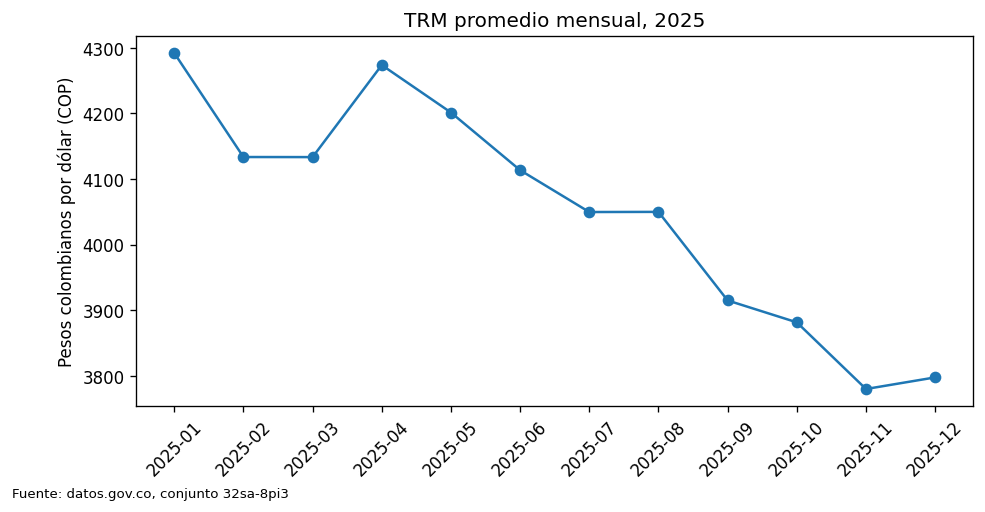


RESUMEN
  [OK   ] buscar_datasets    Buscar conjuntos en el catálogo (0.0 s)
  [OK   ] consultar_dataset  Consultar la TRM agregando en el servidor (0.0 s)
  [OK   ] ejecutar_python    Analizar y graficar con Python (1.1 s)
  [OK   ] calculadora        Cuenta exacta con la calculadora (0.0 s)
  [OK   ] buscar_web         Buscar contexto en la web (1.5 s)
  [OK   ] cargar_skill       Cargar un skill (0.0 s)
  [OK   ] consultar_dataset  Privacidad: columna personal bloqueada (0.0 s)


In [25]:
from pathlib import Path

from IPython.display import Image, display

from lupa.llm.base import LlamadaTool
from lupa.skills import cargar_skills
from lupa.tools import Contexto, crear_registro

contexto_prueba = Contexto(Path("salidas/prueba_tools"))
registro = crear_registro(config, contexto_prueba, cargar_skills())

CODIGO_GRAFICA = """
df = pd.read_csv('tabla_1.csv')
df['mes'] = pd.to_datetime(df['mes']).dt.strftime('%Y-%m')
print(df.to_string(index=False))
plt.figure(figsize=(9, 4))
plt.plot(df['mes'], df['trm'], marker='o')
plt.title('TRM promedio mensual, 2025')
plt.ylabel('Pesos colombianos por dólar (COP)')
plt.xticks(rotation=45)
plt.figtext(0.01, -0.08, 'Fuente: datos.gov.co, conjunto 32sa-8pi3', fontsize=8)
plt.savefig('trm_2025.png', dpi=120, bbox_inches='tight')
"""

PRUEBAS = [
    # (qué se prueba, tool, argumentos, ¿debe fallar?)
    ("Buscar conjuntos en el catálogo", "buscar_datasets",
     {"consulta": "tasa de cambio representativa del mercado", "limite": 2}, False),
    ("Consultar la TRM agregando en el servidor", "consultar_dataset",
     {"dataset_id": "32sa-8pi3",
      "select": "date_trunc_ym(vigenciadesde) AS mes, avg(valor) AS trm",
      "where": "vigenciadesde between '2025-01-01T00:00:00' and '2025-12-31T23:59:59'",
      "group": "mes", "order": "mes"}, False),
    ("Analizar y graficar con Python", "ejecutar_python", {"codigo": CODIGO_GRAFICA}, False),
    ("Cuenta exacta con la calculadora", "calculadora", {"expresion": "(3800.5 - 4300.25) * 1000"}, False),
    ("Buscar contexto en la web", "buscar_web",
     {"consulta": "qué movió el dólar en Colombia en 2025", "max_resultados": 2}, False),
    ("Cargar un skill", "cargar_skill", {"nombre": "explorar_datos"}, False),
    ("Privacidad: columna personal bloqueada", "consultar_dataset",
     {"dataset_id": "jbjy-vk9h", "select": "documento_proveedor", "limit": 1}, True),
]

resumen_pruebas = []
for i, (descripcion, tool, argumentos, debe_fallar) in enumerate(PRUEBAS, 1):
    resultado = registro.ejecutar(LlamadaTool(id=f"prueba-{i}", nombre=tool, argumentos=argumentos))
    paso = (not resultado.ok) if debe_fallar else resultado.ok
    resumen_pruebas.append((descripcion, tool, paso, resultado.duracion_s))
    print("=" * 100)
    print(f"{i}. {descripcion} → {tool}   [{'OK' if paso else 'FALLA'}] ({resultado.duracion_s:.1f} s)")
    print("-" * 100)
    texto = resultado.texto
    print(texto if len(texto) <= 900 else texto[:900] + "\n[...]")

for grafica in contexto_prueba.graficas:
    display(Image(filename=str(grafica)))

print("\nRESUMEN")
for descripcion, tool, paso, segundos in resumen_pruebas:
    print(f"  [{'OK   ' if paso else 'FALLA'}] {tool:<18} {descripcion} ({segundos:.1f} s)")

## 5. Demo del agente
Cada línea de la traza es un paso del ciclo **razonar → actuar → observar**: qué tool pidió el LLM, con qué argumentos y qué obtuvo. Al final se muestran la respuesta, las gráficas y las métricas.

In [26]:
from IPython.display import Image, Markdown, display

from lupa.agent import Agente
from lupa.llm import crear_proveedor

agente = Agente(crear_proveedor(config), config, usar_skills=True)


def preguntar(pregunta):
    """Hace una pregunta al agente y muestra la traza, la respuesta, las gráficas y las métricas."""
    print(f"PREGUNTA: {pregunta}\n")
    for e in agente.responder_por_pasos(pregunta):
        if e.tipo == "pensamiento":
            print(f"[paso {e.paso}] razonamiento: {e.texto[:200]}")
        elif e.tipo == "llamada":
            print(f"[paso {e.paso}] -> {e.tool} {str(e.argumentos)[:200]}")
        elif e.tipo == "resultado":
            print(("     ok    " if e.ok else "     ERROR ") + e.texto[:160].replace("\n", " "))
        elif e.tipo in ("aviso", "error"):
            print(f"[{e.tipo}] {e.texto}")
    res = agente.ultimo_resultado
    # Colab interpreta "$...$" como fórmula matemática: se escapa el signo de pesos
    display(Markdown(res.respuesta.replace("$", r"\$")))
    for g in res.graficas:
        display(Image(filename=str(g)))
    print(f"\nPasos: {res.pasos} · Llamadas al LLM: {res.llamadas_llm} · "
          f"Tokens: {res.tokens_entrada + res.tokens_salida:,} · Tiempo: {res.duracion_s:.0f} s · "
          f"Skills: {', '.join(res.skills_cargados) or 'ninguno'}")
    return res

### 5.1 Consulta puntual y cálculo exacto (TRM + calculadora)

In [18]:
preguntar("Si compré 1.000 dólares el 2 de enero de 2025 y los vendí el 30 de diciembre de 2025, "
          "¿cuánto gané o perdí en pesos?");

PREGUNTA: Si compré 1.000 dólares el 2 de enero de 2025 y los vendí el 30 de diciembre de 2025, ¿cuánto gané o perdí en pesos?



[aviso] gemini-3.5-flash no estaba disponible; sigo con gemini-3.5-flash-lite.
[paso 1] -> cargar_skill {'nombre': 'explorar_datos'}
     ok    # Skill: explorar_datos Tools de este skill: buscar_datasets, consultar_dataset  # Explorar datos  ## Cuándo usarlo Siempre que la pregunta necesite datos y tod
[paso 2] -> consultar_dataset {'dataset_id': '32sa-8pi3', 'where': "vigenciadesde <= '2025-01-02T00:00:00' AND vigenciahasta >= '2025-01-02T23:59:59'"}
     ok    La consulta a 32sa-8pi3 no devolvió filas (se guardó vacía como tabla_1.csv). Revisa el filtro: mayúsculas y tildes, formato de fechas o valores exactos de las 
[paso 3] -> consultar_dataset {'order': 'vigenciadesde DESC', 'limit': 5, 'dataset_id': '32sa-8pi3'}
     ok    Consulta a 32sa-8pi3: 5 filas × 4 columnas. Guardada como tabla_2.csv (en ejecutar_python: pd.read_csv('tabla_2.csv')). Columnas: valor (número), unidad (texto)
[paso 4] -> consultar_dataset {'dataset_id': '32sa-8pi3', 'where': "vigenciadesde like '2025-01-02

**Respuesta:** Si hubieras comprado 1.000 dólares el 2 de enero de 2025 y los hubieras vendido el 30 de diciembre de 2025, **habrías perdido 702.180 pesos** (una variación negativa de 15,93% en el capital invertido).

### Hallazgos
- **TRM inicial (2 de enero de 2025):** 4.409,15 pesos por dólar. Invertir 1.000 dólares requirió 4.409.150 pesos.
- **TRM final (30 de diciembre de 2025):** 3.706,97 pesos por dólar. Vender los 1.000 dólares en esa fecha recuperó 3.706.970 pesos.
- **Pérdida neta:** -702.180 pesos (equivalente a -15,93%).

### Fuentes
- **Unidad de Valor Tributario y TRM (Superfinanciera):** Valores históricos de la Tasa Representativa del Mercado (TRM), conjunto `32sa-8pi3`, disponible en [datos.gov.co](https://www.datos.gov.co/d/32sa-8pi3).

### Limitaciones
- La TRM del 2 de enero de 2025 rigió bajo la vigencia del 31 de diciembre de 2024 al 2 de enero de 2025, debido a los días festivos de fin de año.
- Los cálculos no incluyen costos de transacción, comisiones bancarias ni diferencias entre la tasa oficial (TRM) y las tasas efectivas de compra o venta en casas de cambio o entidades financieras.


Pasos: 11 · Llamadas al LLM: 11 · Tokens: 43,701 · Tiempo: 40 s · Skills: explorar_datos, redaccion_informe


### 5.2 Memoria de la conversación
La pregunta no repite las fechas: el agente debe recordarlas de la anterior.

In [19]:
preguntar("¿Y si hubieran sido 5.000 dólares?");

PREGUNTA: ¿Y si hubieran sido 5.000 dólares?

[paso 1] -> calculadora {'expresion': '-70218.0 * 50'}
     ok    -70218.0 * 50 = -3510900 (en formato colombiano: -3.510.900)


[paso 2] -> calculadora {'expresion': '-702180 * 5'}
     ok    -702180 * 5 = -3510900 (en formato colombiano: -3.510.900)


**Respuesta:** Si hubieras comprado y vendido **5.000 dólares** en esas mismas fechas (2 de enero de 2025 y 30 de diciembre de 2025), **habrías perdido 3.510.900 pesos** (mantiene la misma pérdida porcentual del 15,93%).

### Desglose de la operación con 5.000 dólares:
- **Inversión inicial (2 de enero de 2025 a TRM de 4.409,15 pesos):** 22.045.750 pesos.
- **Valor de venta (30 de diciembre de 2025 a TRM de 3.706,97 pesos):** 18.534.850 pesos.
- **Pérdida neta:** -3.510.900 pesos.

### Fuentes
- **Unidad de Valor Tributario y TRM (Superfinanciera):** Valores históricos de la Tasa Representativa del Mercado (TRM), conjunto `32sa-8pi3`, disponible en [datos.gov.co](https://www.datos.gov.co/d/32sa-8pi3).

### Limitaciones
- Los cálculos se basan exclusivamente en la Tasa Representativa del Mercado (TRM) oficial y no contemplan comisiones, spreads bancarios ni costos operativos de conversión de divisas.


Pasos: 3 · Llamadas al LLM: 3 · Tokens: 6,875 · Tiempo: 44 s · Skills: ninguno


### 5.3 Tarea compleja: datos + gráfica + web + informe

PREGUNTA: ¿Cuánto contrató la Gobernación del Valle del Cauca por SECOP II en 2025, por dependencia? Muestra una gráfica de las 5 dependencias con mayor valor y busca si hubo noticias sobre esa contratación.

[paso 1] -> cargar_skill {'nombre': 'explorar_datos'}
     ok    # Skill: explorar_datos Tools de este skill: buscar_datasets, consultar_dataset  # Explorar datos  ## Cuándo usarlo Siempre que la pregunta necesite datos y tod
[paso 2] -> consultar_dataset {'group': 'nombre_entidad', 'order': 'total DESC', 'limit': 50, 'dataset_id': 'jbjy-vk9h', 'select': 'nombre_entidad, sum(valor_del_contrato) AS total, count(*) AS num_contratos', 'where': "upper(nomb
     ok    Consulta a jbjy-vk9h: 50 filas × 3 columnas. Guardada como tabla_6.csv (en ejecutar_python: pd.read_csv('tabla_6.csv')). Columnas: nombre_entidad (texto), total
[paso 3] -> cargar_skill {'nombre': 'analisis_estadistico'}
     ok    # Skill: analisis_estadistico Tools de este skill: consultar_dataset, ejecutar_python, calc

**Respuesta:** Durante el año 2025, la Gobernación del Valle del Cauca contrató un total de **1.339.992.833.003,21 pesos** (aproximadamente 1,34 billones de pesos) a través de SECOP II, distribuidos entre sus diferentes dependencias y secretarías.

---

### Hallazgos
- **Secretaría de Infraestructura:** Es la dependencia que mayor valor contrató, alcanzando **483.350.764.038 pesos** en 893 contratos (el 36 % del total departamental).
- **Secretaría de Vivienda y Hábitat:** Ocupa el segundo lugar con **202.908.094.033 pesos** distribuidos en 613 contratos.
- **DADI (Departamento Administrativo):** Tercer lugar con **180.291.031.538,01 pesos** en 4.056 contratos.
- **Secretaría de Educación:** Cuarto puesto con **176.764.232.218,46 pesos** en 2.036 contratos.
- **Hacienda (Gobvalle):** Quinto lugar con **93.750.104.892 pesos** en 425 contratos.

---

### Gráfica
La gráfica **`contratos_valle_2025.png`** muestra el ranking de las 5 dependencias con mayor valor contratado. Se observa cómo la Secretaría de Infraestructura supera ampliamente a las demás secretarías del departamento.

---

### Contexto
No se identificaron noticias de carácter crítico o judicial específicas sobre la contratación general de 2025 de la Gobernación del Valle en las búsquedas recientes; la cobertura institucional se limita a reportes generales de gestión sobre atención ciudadana y lineamientos de transparencia en plataformas de contratación estatal [Gobernación del Valle](https://www.valledelcauca.gov.co/publicaciones/91128/en-un-ano-las-quejas-en-la-gobernacion-del-valle-cayeron-88-y-las-felicitaciones-aumentaron-78).

---

### Fuentes
- **Datos abiertos:** SECOP II - Contratos Electrónicos (conjunto `jbjy-vk9h`), disponible en [datos.gov.co](https://www.datos.gov.co/d/jbjy-vk9h).
- **Web:** [Gobernación del Valle del Cauca](https://www.valledelcauca.gov.co).

---

### Limitaciones
- Los datos corresponden a los contratos firmados en el SECOP II entre el 1 de enero y el 31 de diciembre de 2025 según el filtro aplicado.
- La nomenclatura de las dependencias en la plataforma de datos abiertos puede incluir variaciones menores en la denominación exacta registrada por cada secretaría.

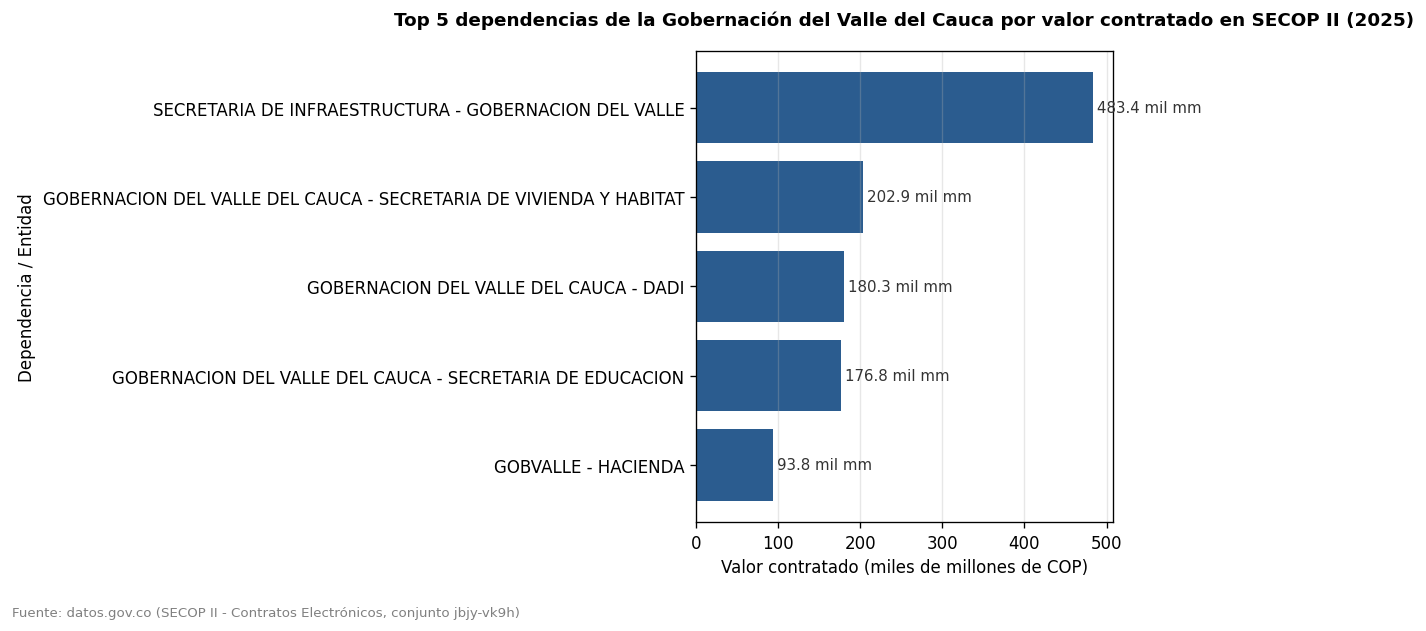


Pasos: 15 · Llamadas al LLM: 15 · Tokens: 132,208 · Tiempo: 69 s · Skills: explorar_datos, analisis_estadistico, visualizacion, investigacion_web, redaccion_informe


In [20]:
agente.reiniciar()   # empieza una conversación nueva
preguntar("¿Cuánto contrató la Gobernación del Valle del Cauca por SECOP II en 2025, por dependencia? "
          "Muestra una gráfica de las 5 dependencias con mayor valor y busca si hubo noticias sobre esa contratación.");

## 6. Interfaz web
Abre el enlace público (`https://….gradio.live`) que aparece abajo. A la izquierda está el chat; a la derecha, las gráficas, la traza del agente y las métricas.
La celda se queda ejecutándose mientras la interfaz esté abierta: para seguir con el notebook, detenla con el botón ⏹.

In [27]:
from lupa.ui.app import construir_app

construir_app(config).queue().launch(share=True, allowed_paths=[str(CARPETA / "salidas")], debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d8c34d0140e4002e4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://d8c34d0140e4002e4e.gradio.live


## 7. Evaluación con y sin skills
Corre las 12 tareas de `eval/tareas.json` dos veces (**sin skills** y **con skills**) y compara la tasa de éxito, el uso de tools, los pasos, los errores recuperados, el tiempo y los tokens. Las respuestas esperadas se calculan en el momento con una consulta directa a datos.gov.co.

La evaluación completa hace entre 150 y 250 llamadas al LLM, más de lo que suele permitir la capa gratuita en un día. Por eso está **dividida en 3 partes**: corre una parte, y si aparece el error 429 (cuota agotada), sigue con la siguiente otro día. La cuota diaria se reinicia a la medianoche hora del Pacífico (3:00 a. m. en Colombia).

Los resultados se borran cuando Colab se reinicia: **después de cada parte corre la celda 7.5** para descargarlos.

### 7.1 Parte 1: tareas simples

In [28]:
from lupa.evaluacion import main as evaluar

evaluar(["--tareas", "S1,S2,S3,S4", "--pausa", "8"]);

[1/8] sin_skills · S1: ¿Cuál fue la TRM vigente el 2 de enero de 2025?…


      OK    8 pasos · 28 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 4,409.15'}]
[2/8] sin_skills · S2: ¿Cuál fue la TRM promedio de octubre de 2025?…


      OK    8 pasos · 44 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 3,881.44'}]
[3/8] sin_skills · S3: ¿Cuántos contratos firmó en 2025 la Secretaría de Infraestructura de l…


      OK    7 pasos · 36 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 893.00'}]
[4/8] sin_skills · S4: ¿Qué conjunto de datos de datos.gov.co tiene los resultados de las pru…


      OK    3 pasos · 7 s · [{'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]
[5/8] con_skills · S1: ¿Cuál fue la TRM vigente el 2 de enero de 2025?…


      OK    9 pasos · 25 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 4,409.15'}]
[6/8] con_skills · S2: ¿Cuál fue la TRM promedio de octubre de 2025?…


      OK    5 pasos · 12 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 3,881.44'}]
[7/8] con_skills · S3: ¿Cuántos contratos firmó en 2025 la Secretaría de Infraestructura de l…


      OK    5 pasos · 92 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 893.00'}]
[8/8] con_skills · S4: ¿Qué conjunto de datos de datos.gov.co tiene los resultados de las pru…


      OK    4 pasos · 28 s · [{'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]

Listo. Resultados en /content/lupa-agente/eval/resultados/20261126-130143
# Resultados de la evaluación (2026-11-26 13:07)

Proveedor: gemini · Tareas: 4 por configuración

| Métrica | Sin skills | Con skills |
| --- | --- | --- |
| Tasa de éxito (total) | 100 % | 100 % |
| Éxito: simples | 100 % | 100 % |
| Éxito: varios pasos | — | — |
| Éxito: complejas | — | — |
| Uso correcto de tools | 74 % | 100 % |
| Pasos por tarea (promedio) | 6.5 | 5.8 |
| Errores de tools / recuperados | 2 / 2 | 2 / 2 |
| Tiempo por tarea (promedio) | 28 s | 39 s |
| Tokens por tarea (promedio) | 26,052 | 20,476 |




### 7.2 Parte 2: tareas de varios pasos

In [29]:
evaluar(["--tareas", "M1,M2,M3,M4", "--pausa", "8"]);

[1/8] sin_skills · M1: Si compré 1.000 dólares el 2 de enero de 2025 y los vendí el 30 de dic…


      OK    6 pasos · 15 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ -702,180.00'}]
[2/8] sin_skills · M2: ¿En qué mes de 2025 fue más alta la TRM promedio y cuál fue ese promed…


      OK    11 pasos · 133 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 4,292.27'}, {'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]
[3/8] sin_skills · M3: ¿Cuánto sumaron en 2025 los contratos firmados en SECOP II por la Secr…


      FALLA 15 pasos · 106 s · [{'tipo': 'numero', 'ok': False, 'detalle': 'esperado ≈ 224,026,434,814.00'}]
[4/8] sin_skills · M4: Grafica la TRM promedio mensual de 2025.…


      OK    6 pasos · 10 s · [{'tipo': 'dataset', 'ok': True, 'detalle': "consultó ['32sa-8pi3']"}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}]
[5/8] con_skills · M1: Si compré 1.000 dólares el 2 de enero de 2025 y los vendí el 30 de dic…


      OK    10 pasos · 69 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ -702,180.00'}]
[6/8] con_skills · M2: ¿En qué mes de 2025 fue más alta la TRM promedio y cuál fue ese promed…


      OK    6 pasos · 21 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 4,292.27'}, {'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]
[7/8] con_skills · M3: ¿Cuánto sumaron en 2025 los contratos firmados en SECOP II por la Secr…


      OK    6 pasos · 49 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 224,026,434,814.00'}]
[8/8] con_skills · M4: Grafica la TRM promedio mensual de 2025.…


      OK    6 pasos · 16 s · [{'tipo': 'dataset', 'ok': True, 'detalle': "consultó ['32sa-8pi3']"}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}]

Listo. Resultados en /content/lupa-agente/eval/resultados/20261126-130724
# Resultados de la evaluación (2026-11-26 13:15)

Proveedor: gemini · Tareas: 4 por configuración

| Métrica | Sin skills | Con skills |
| --- | --- | --- |
| Tasa de éxito (total) | 75 % | 100 % |
| Éxito: simples | — | — |
| Éxito: varios pasos | 75 % | 100 % |
| Éxito: complejas | — | — |
| Uso correcto de tools | 47 % | 95 % |
| Pasos por tarea (promedio) | 9.5 | 7.0 |
| Errores de tools / recuperados | 2 / 2 | 0 / 0 |
| Tiempo por tarea (promedio) | 66 s | 39 s |
| Tokens por tarea (promedio) | 64,890 | 25,743 |




### 7.3 Parte 3: tareas complejas

In [30]:
evaluar(["--tareas", "C1,C2,C3,C4", "--pausa", "8"]);

[1/8] sin_skills · C1: ¿Cuánto contrató en total la Gobernación del Valle del Cauca, sumando …


      FALLA 11 pasos · 57 s · [{'tipo': 'numero', 'ok': False, 'detalle': 'esperado ≈ 1,530,717,006,754.22'}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}]
[2/8] sin_skills · C2: Compara el puntaje global promedio de Saber 11 entre colegios oficiale…


      FALLA 10 pasos · 136 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 241.87'}, {'tipo': 'numero', 'ok': False, 'detalle': 'esperado ≈ 261.19'}]
[3/8] sin_skills · C3: Grafica la TRM promedio mensual de 2025 y busca en la web qué factores…


      OK    8 pasos · 26 s · [{'tipo': 'dataset', 'ok': True, 'detalle': "consultó ['32sa-8pi3']"}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}, {'tipo': 'web', 'ok': True, 'detalle': 'usó buscar_web y citó enlaces'}]
[4/8] sin_skills · C4: ¿Qué datos abiertos hay sobre calidad del aire en Bogotá? Elige el con…


      OK    15 pasos · 91 s · [{'tipo': 'tools_exitosas', 'ok': True, 'detalle': 'ok'}, {'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]
[5/8] con_skills · C1: ¿Cuánto contrató en total la Gobernación del Valle del Cauca, sumando …


      FALLA 11 pasos · 168 s · [{'tipo': 'numero', 'ok': False, 'detalle': 'esperado ≈ 1,530,717,006,754.22'}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}]
[6/8] con_skills · C2: Compara el puntaje global promedio de Saber 11 entre colegios oficiale…


      OK    8 pasos · 25 s · [{'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 241.87'}, {'tipo': 'numero', 'ok': True, 'detalle': 'esperado ≈ 261.19'}]
[7/8] con_skills · C3: Grafica la TRM promedio mensual de 2025 y busca en la web qué factores…


      OK    9 pasos · 33 s · [{'tipo': 'dataset', 'ok': True, 'detalle': "consultó ['32sa-8pi3']"}, {'tipo': 'grafica', 'ok': True, 'detalle': '1 gráficas'}, {'tipo': 'web', 'ok': True, 'detalle': 'usó buscar_web y citó enlaces'}]
[8/8] con_skills · C4: ¿Qué datos abiertos hay sobre calidad del aire en Bogotá? Elige el con…


      OK    10 pasos · 49 s · [{'tipo': 'tools_exitosas', 'ok': True, 'detalle': 'ok'}, {'tipo': 'contiene', 'ok': True, 'detalle': 'ok'}]

Listo. Resultados en /content/lupa-agente/eval/resultados/20261126-131532
# Resultados de la evaluación (2026-11-26 13:26)

Proveedor: gemini · Tareas: 4 por configuración

| Métrica | Sin skills | Con skills |
| --- | --- | --- |
| Tasa de éxito (total) | 50 % | 75 % |
| Éxito: simples | — | — |
| Éxito: varios pasos | — | — |
| Éxito: complejas | 50 % | 75 % |
| Uso correcto de tools | 66 % | 91 % |
| Pasos por tarea (promedio) | 11.0 | 9.5 |
| Errores de tools / recuperados | 5 / 5 | 0 / 0 |
| Tiempo por tarea (promedio) | 78 s | 69 s |
| Tokens por tarea (promedio) | 72,666 | 53,118 |




### 7.4 Juntar las partes y ver el resultado
Une todas las corridas que haya en `eval/resultados/`. Si subiste corridas de otro día (celda 7.6), también entran.

Corridas encontradas: 20261126-113653, 20261126-115930, 20261126-121012, 20261126-130143, 20261126-130724, 20261126-131532
Listo. Resultados combinados en /content/lupa-agente/eval/resultados/combinado-20261126-132628
# Resultados de la evaluación (2026-11-26 13:26)

Proveedor: gemini · Tareas: 12 por configuración

| Métrica | Sin skills | Con skills |
| --- | --- | --- |
| Tasa de éxito (total) | 75 % | 92 % |
| Éxito: simples | 100 % | 100 % |
| Éxito: varios pasos | 75 % | 100 % |
| Éxito: complejas | 50 % | 75 % |
| Uso correcto de tools | 62 % | 95 % |
| Pasos por tarea (promedio) | 9.0 | 7.4 |
| Errores de tools / recuperados | 9 / 9 | 2 / 2 |
| Tiempo por tarea (promedio) | 57 s | 49 s |
| Tokens por tarea (promedio) | 54,536 | 33,112 |




# Resultados de la evaluación (2026-11-26 13:26)

Proveedor: gemini · Tareas: 12 por configuración

| Métrica | Sin skills | Con skills |
| --- | --- | --- |
| Tasa de éxito (total) | 75 % | 92 % |
| Éxito: simples | 100 % | 100 % |
| Éxito: varios pasos | 75 % | 100 % |
| Éxito: complejas | 50 % | 75 % |
| Uso correcto de tools | 62 % | 95 % |
| Pasos por tarea (promedio) | 9.0 | 7.4 |
| Errores de tools / recuperados | 9 / 9 | 2 / 2 |
| Tiempo por tarea (promedio) | 57 s | 49 s |
| Tokens por tarea (promedio) | 54,536 | 33,112 |

## Detalle por tarea

| Tarea | Configuración | Éxito | Pasos | Tools | Chequeos |
| --- | --- | --- | --- | --- | --- |
| C1 | Con skills | no | 11 | cargar_skill, consultar_dataset, cargar_skill, consultar_dataset, consultar_dataset, consultar_dataset, cargar_skill, ejecutar_python, ejecutar_python, cargar_skill | numero: falla (esperado ≈ 1,530,717,006,754.22); grafica: ok (1 gráficas) |
| C2 | Con skills | sí | 8 | cargar_skill, consultar_dataset, cargar_skill, calculadora, cargar_skill, ejecutar_python, cargar_skill | numero: ok (esperado ≈ 241.87); numero: ok (esperado ≈ 261.19) |
| C3 | Con skills | sí | 9 | cargar_skill, consultar_dataset, cargar_skill, ejecutar_python, cargar_skill, buscar_web, buscar_web, cargar_skill | dataset: ok (consultó ['32sa-8pi3']); grafica: ok (1 gráficas); web: ok (usó buscar_web y citó enlaces) |
| C4 | Con skills | sí | 10 | cargar_skill, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, ejecutar_python, consultar_dataset, ejecutar_python, cargar_skill | tools_exitosas: ok (ok); contiene: ok (ok) |
| M1 | Con skills | sí | 10 | cargar_skill, consultar_dataset, consultar_dataset, cargar_skill, calculadora, calculadora, calculadora, calculadora, cargar_skill | numero: ok (esperado ≈ -702,180.00) |
| M2 | Con skills | sí | 6 | cargar_skill, consultar_dataset, cargar_skill, cargar_skill, calculadora | numero: ok (esperado ≈ 4,292.27); contiene: ok (ok) |
| M3 | Con skills | sí | 6 | cargar_skill, consultar_dataset, consultar_dataset, cargar_skill, consultar_dataset | numero: ok (esperado ≈ 224,026,434,814.00) |
| M4 | Con skills | sí | 6 | cargar_skill, consultar_dataset, cargar_skill, ejecutar_python, cargar_skill | dataset: ok (consultó ['32sa-8pi3']); grafica: ok (1 gráficas) |
| S1 | Con skills | sí | 9 | cargar_skill, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, cargar_skill | numero: ok (esperado ≈ 4,409.15) |
| S2 | Con skills | sí | 5 | cargar_skill, cargar_skill, consultar_dataset, cargar_skill | numero: ok (esperado ≈ 3,881.44) |
| S3 | Con skills | sí | 5 | cargar_skill, consultar_dataset, consultar_dataset, cargar_skill | numero: ok (esperado ≈ 893.00) |
| S4 | Con skills | sí | 4 | cargar_skill, buscar_datasets, cargar_skill | contiene: ok (ok) |
| C1 | Sin skills | no | 11 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, ejecutar_python, ejecutar_python, calculadora, ejecutar_python | numero: falla (esperado ≈ 1,530,717,006,754.22); grafica: ok (1 gráficas) |
| C2 | Sin skills | no | 10 | buscar_datasets, buscar_datasets, buscar_web, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, ejecutar_python, calculadora | numero: ok (esperado ≈ 241.87); numero: falla (esperado ≈ 261.19) |
| C3 | Sin skills | sí | 8 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, ejecutar_python, ejecutar_python, buscar_web | dataset: ok (consultó ['32sa-8pi3']); grafica: ok (1 gráficas); web: ok (usó buscar_web y citó enlaces) |
| C4 | Sin skills | sí | 15 | buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, ejecutar_python, consultar_dataset, ejecutar_python, ejecutar_python | tools_exitosas: ok (ok); contiene: ok (ok) |
| M1 | Sin skills | sí | 6 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, calculadora | numero: ok (esperado ≈ -702,180.00) |
| M2 | Sin skills | sí | 11 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, ejecutar_python, ejecutar_python, consultar_dataset, ejecutar_python, ejecutar_python | numero: ok (esperado ≈ 4,292.27); contiene: ok (ok) |
| M3 | Sin skills | no | 15 | buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset | numero: falla (esperado ≈ 224,026,434,814.00) |
| M4 | Sin skills | sí | 6 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, ejecutar_python | dataset: ok (consultó ['32sa-8pi3']); grafica: ok (1 gráficas) |
| S1 | Sin skills | sí | 8 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset | numero: ok (esperado ≈ 4,409.15) |
| S2 | Sin skills | sí | 8 | buscar_datasets, consultar_dataset, consultar_dataset, ejecutar_python, consultar_dataset, consultar_dataset, ejecutar_python | numero: ok (esperado ≈ 3,881.44) |
| S3 | Sin skills | sí | 7 | buscar_datasets, buscar_datasets, consultar_dataset, consultar_dataset, consultar_dataset, consultar_dataset | numero: ok (esperado ≈ 893.00) |
| S4 | Sin skills | sí | 3 | buscar_datasets, buscar_datasets | contiene: ok (ok) |


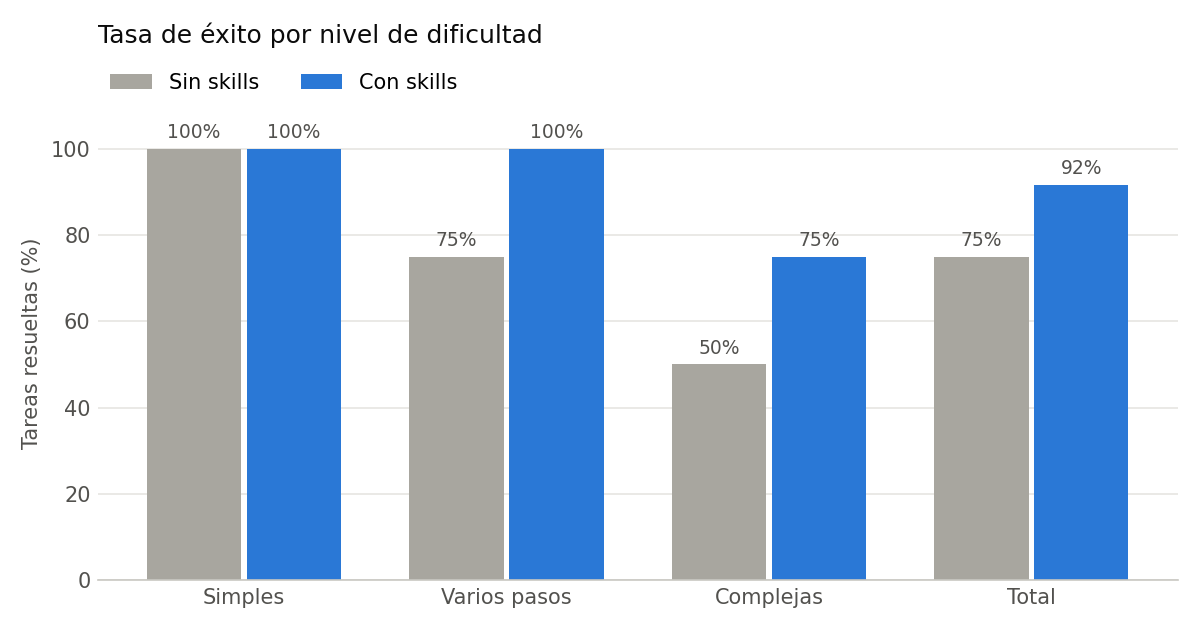

In [31]:
from pathlib import Path

from IPython.display import Image, Markdown, display

carpeta_resultados = CARPETA / "eval" / "resultados"
carpeta_resultados.mkdir(parents=True, exist_ok=True)
partes = sorted(p for p in carpeta_resultados.iterdir()
                if p.is_dir() and not p.name.startswith("combinado") and (p / "resultados.json").exists())
print("Corridas encontradas:", ", ".join(p.name for p in partes) or "ninguna")

if partes:
    evaluar(["--unir", *map(str, partes)])
    ultima = sorted(carpeta_resultados.glob("combinado-*"))[-1]
    display(Markdown((ultima / "resumen.md").read_text(encoding="utf-8")))
    display(Image(filename=str(ultima / "exito_por_nivel.png")))

### 7.5 Descargar los resultados

In [32]:
import shutil

from google.colab import files

archivo = shutil.make_archive("/content/resultados_evaluacion", "zip", CARPETA / "eval" / "resultados")
files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.6 Subir resultados de otro día (opcional)
Si corriste una parte en otra sesión de Colab, sube aquí el `resultados_evaluacion.zip` que descargaste y luego vuelve a correr la celda 7.4.

In [34]:
import zipfile

from google.colab import files

for nombre in files.upload():
    with zipfile.ZipFile(nombre) as z:
        z.extractall(CARPETA / "eval" / "resultados")
print("Listo. Ahora corre la celda 7.4.")

Saving resultados_evaluacion (1).zip to resultados_evaluacion (1).zip
Listo. Ahora corre la celda 7.4.
